PROFESSION counts:
 Profession
Student             27870
Architect               8
Teacher                 6
Digital Marketer        3
Chef                    2
Name: count, dtype: int64

=== A. MAIN RESULTS, leakage-free imputation (compare with Table II) ===
FULL LR: AUC=0.918 [0.912-0.926] Acc=0.843 P=0.879 R=0.848 F1=0.863
FULL RF: AUC=0.913 [0.906-0.921] Acc=0.840 P=0.850 R=0.882 F1=0.866
FULL XGB: AUC=0.912 [0.904-0.919] Acc=0.841 P=0.855 R=0.878 F1=0.866
CV LR: 0.922 +/- 0.002
CV RF: 0.912 +/- 0.002
CV XGB: 0.909 +/- 0.002

=== B. SENSITIVITY: without suicidal-thought history ===
NO-SUICIDAL LR: AUC=0.866 [0.857-0.875] Acc=0.793 P=0.842 R=0.796 F1=0.818
NO-SUICIDAL RF: AUC=0.857 [0.848-0.867] Acc=0.787 P=0.805 R=0.839 F1=0.822
NO-SUICIDAL XGB: AUC=0.856 [0.846-0.866] Acc=0.790 P=0.809 R=0.841 F1=0.824
Top-5 after exclusion:
 Stress Index         0.471710
Academic Pressure    0.065492
Dietary Habits       0.063676
Age                  0.046266
Work/Study Hours     0.041023
dtype:

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


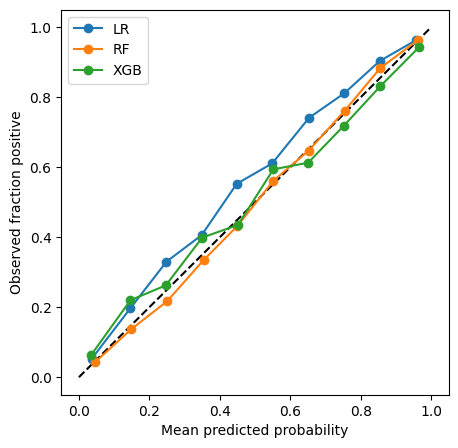

LR isotonic-calibrated: Brier=0.1108 ECE=0.0088
RF isotonic-calibrated: Brier=0.1140 ECE=0.0091
XGB isotonic-calibrated: Brier=0.1140 ECE=0.0137

=== E. THRESHOLD ANALYSIS ===
LR highest threshold giving recall>=0.90: 0.36000000000000004
RF highest threshold giving recall>=0.90: 0.45
XGB highest threshold giving recall>=0.90: 0.42000000000000004
Model  Thr  Prec   Rec    F1
   LR  0.3 0.820 0.925 0.869
   LR  0.4 0.856 0.888 0.872
   LR  0.5 0.879 0.848 0.863
   LR  0.6 0.904 0.797 0.847
   LR  0.7 0.924 0.726 0.813
   RF  0.3 0.782 0.950 0.858
   RF  0.4 0.815 0.922 0.865
   RF  0.5 0.850 0.882 0.866
   RF  0.6 0.878 0.829 0.853
   RF  0.7 0.907 0.761 0.828
  XGB  0.3 0.807 0.931 0.865
  XGB  0.4 0.829 0.908 0.866
  XGB  0.5 0.855 0.878 0.866
  XGB  0.6 0.874 0.836 0.855
  XGB  0.7 0.897 0.789 0.840

=== F. EXTENDED BENCHMARK ===
EXT HistGB: AUC=0.916 [0.909-0.924] Acc=0.841 P=0.855 R=0.876 F1=0.865
EXT ExtraTrees: AUC=0.906 [0.898-0.913] Acc=0.829 P=0.842 R=0.872 F1=0.857
EXT MLP: AU

In [ ]:
# ===== Revision analyses for reviewer comments (run in Google Colab) =====
# Upload "Student Depression Dataset.csv" to Colab first (left sidebar > Files > upload).
import pandas as pd, numpy as np, warnings; warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score, brier_score_loss
from xgboost import XGBClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor
SEED=42
df=pd.read_csv('/content/Student Depression Dataset.csv')

# --- Profession check (reviewer 1, point 8)
print('PROFESSION counts:\n', df['Profession'].value_counts().head())

# --- cleaning (row-wise only, so no leakage) ---
for c in ['Sleep Duration','Dietary Habits']: df[c]=df[c].astype(str).str.strip("' ")
sleep={'Less than 5 hours':1,'5-6 hours':2,'7-8 hours':3,'More than 8 hours':4}
diet={'Unhealthy':1,'Moderate':2,'Healthy':3}
df['Sleep Duration']=df['Sleep Duration'].map(sleep); df['Dietary Habits']=df['Dietary Habits'].map(diet)
sc=[c for c in df.columns if 'suicidal' in c][0]
df['Suicidal']=df[sc].map({'Yes':1,'No':0})
df['FamHist']=df['Family History of Mental Illness'].map({'Yes':1,'No':0})
df['Financial Stress']=pd.to_numeric(df['Financial Stress'],errors='coerce')
def dg(x):
    x=str(x).lower()
    if 'class 12' in x: return 'School'
    if x.startswith('b') or 'b.' in x: return 'UG'
    if x.startswith('m') or 'm.' in x or 'llm' in x: return 'PG'
    if 'phd' in x: return 'Doc'
    return 'Others'
# !! If you have your ORIGINAL Degree-mapping code, paste it here instead of dg() !!
df['DegreeGroup']=df['Degree'].map(dg)
df['Stress Index']=df[['Academic Pressure','Financial Stress','Work Pressure']].mean(axis=1)
df['Lifestyle Score']=df[['Sleep Duration','Dietary Habits']].mean(axis=1)
df['Gender']=(df['Gender']=='Male').astype(int)
df=pd.concat([df,pd.get_dummies(df['DegreeGroup'],prefix='Deg').astype(int)],axis=1)
base=['Gender','Age','Academic Pressure','CGPA','Study Satisfaction','Work/Study Hours','Sleep Duration',
      'Dietary Habits','Financial Stress','Suicidal','FamHist']+[c for c in df if c.startswith('Deg_')]
comp=['Stress Index','Lifestyle Score']; y=df['Depression']
X_all=df[base+comp]
Xtr,Xte,ytr,yte=train_test_split(X_all,y,test_size=0.2,stratify=y,random_state=SEED)  # SPLIT BEFORE IMPUTATION

def models():
    return {'LR':make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),LogisticRegression(class_weight='balanced',max_iter=1000)),
     'RF':make_pipeline(SimpleImputer(strategy='median'),RandomForestClassifier(300,class_weight='balanced',random_state=SEED,n_jobs=-1)),
     'XGB':make_pipeline(SimpleImputer(strategy='median'),XGBClassifier(eval_metric='logloss',random_state=SEED))}
def boot_ci(yt,p,n=1000):
    r=np.random.RandomState(SEED); a=[]
    for _ in range(n):
        i=r.randint(0,len(yt),len(yt)); a.append(roc_auc_score(yt.iloc[i],p[i]))
    return np.percentile(a,[2.5,97.5])
def evaluate(Xtr,Xte,ms,tag):
    out={}
    for k,m in ms.items():
        m.fit(Xtr,ytr); p=m.predict_proba(Xte)[:,1]; pr=(p>=.5).astype(int); out[k]=(m,p)
        lo,hi=boot_ci(yte,p)
        print(f'{tag} {k}: AUC={roc_auc_score(yte,p):.3f} [{lo:.3f}-{hi:.3f}] Acc={(pr==yte).mean():.3f} '
              f'P={precision_score(yte,pr):.3f} R={recall_score(yte,pr):.3f} F1={f1_score(yte,pr):.3f}')
    return out

print('\n=== A. MAIN RESULTS, leakage-free imputation (compare with Table II) ===')
main=evaluate(Xtr,Xte,models(),'FULL')
cv=StratifiedKFold(5,shuffle=True,random_state=SEED)
for k,m in models().items():
    s=cross_val_score(m,Xtr,ytr,cv=cv,scoring='roc_auc'); print(f'CV {k}: {s.mean():.3f} +/- {s.std():.3f}')

print('\n=== B. SENSITIVITY: without suicidal-thought history ===')
cols=[c for c in X_all if c!='Suicidal']
evaluate(Xtr[cols],Xte[cols],models(),'NO-SUICIDAL')
x=models()['XGB'].fit(Xtr[cols],ytr); imp=pd.Series(x[-1].feature_importances_,index=cols).sort_values(ascending=False)
print('Top-5 after exclusion:\n',imp.head(5))

print('\n=== C. ABLATION of engineered features (5-fold CV AUC on train) ===')
sets={'full':base+comp,'no_composites':base,
      'composites_replace':[c for c in base if c not in ['Academic Pressure','Financial Stress','Sleep Duration','Dietary Habits']]+comp}
for name,cs in sets.items():
    for k,m in models().items():
        s=cross_val_score(m,Xtr[cs],ytr,cv=cv,scoring='roc_auc'); print(f'{name:20s} {k}: {s.mean():.3f} +/- {s.std():.3f}')
v=X_all[comp+['Academic Pressure','Financial Stress','Sleep Duration','Dietary Habits']].dropna()
print('VIF:',{c:round(variance_inflation_factor(v.values,i),1) for i,c in enumerate(v.columns)})

print('\n=== D. CALIBRATION ===')
fig,ax=plt.subplots(figsize=(5,5)); ax.plot([0,1],[0,1],'k--')
def ece(yt,p,b=10):
    bins=np.linspace(0,1,b+1); idx=np.digitize(p,bins[1:-1]); e=0
    for i in range(b):
        m=idx==i
        if m.sum(): e+=m.mean()*abs(yt[m].mean()-p[m].mean())
    return e
for k,(m,p) in main.items():
    print(f'{k}: Brier={brier_score_loss(yte,p):.4f} ECE={ece(yte.values,p):.4f}')
    f,mp=calibration_curve(yte,p,n_bins=10); ax.plot(mp,f,marker='o',label=k)
ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Observed fraction positive'); ax.legend()
plt.savefig('fig7_calibration.png',dpi=300,bbox_inches='tight'); plt.show()
for k in ['LR','RF','XGB']:
    cal=CalibratedClassifierCV(models()[k],method='isotonic',cv=5).fit(Xtr,ytr); p=cal.predict_proba(Xte)[:,1]
    print(f'{k} isotonic-calibrated: Brier={brier_score_loss(yte,p):.4f} ECE={ece(yte.values,p):.4f}')

print('\n=== E. THRESHOLD ANALYSIS ===')
rows=[]
for k,(m,p) in main.items():
    for t in [.3,.4,.5,.6,.7]:
        pr=(p>=t).astype(int); rows.append([k,t,precision_score(yte,pr),recall_score(yte,pr),f1_score(yte,pr)])
    ts=np.linspace(.01,.99,99); t90=max([t for t in ts if recall_score(yte,(p>=t).astype(int))>=.90],default=None)
    print(k,'highest threshold giving recall>=0.90:',t90)
print(pd.DataFrame(rows,columns=['Model','Thr','Prec','Rec','F1']).round(3).to_string(index=False))

print('\n=== F. EXTENDED BENCHMARK ===')
ext={'HistGB':make_pipeline(SimpleImputer(strategy='median'),HistGradientBoostingClassifier(random_state=SEED)),
     'ExtraTrees':make_pipeline(SimpleImputer(strategy='median'),ExtraTreesClassifier(300,class_weight='balanced',random_state=SEED,n_jobs=-1)),
     'MLP':make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),MLPClassifier((64,32),max_iter=300,random_state=SEED))}
evaluate(Xtr,Xte,ext,'EXT')
print('\nDONE - copy ALL the printed output back to Claude.')


=== TABLE IV (top 10 by RF importance) ===
                       RF    XGB
Suicidal            0.206  0.658
Stress Index        0.156  0.136
Academic Pressure   0.098  0.026
CGPA                0.098  0.010
Age                 0.088  0.018
Work/Study Hours    0.077  0.015
Financial Stress    0.056  0.010
Study Satisfaction  0.048  0.015
Lifestyle Score     0.037  0.014
Dietary Habits      0.030  0.021

=== Top 10 by XGB importance ===
                       RF    XGB
Suicidal            0.206  0.658
Stress Index        0.156  0.136
Academic Pressure   0.098  0.026
Dietary Habits      0.030  0.021
Age                 0.088  0.018
Study Satisfaction  0.048  0.015
Work/Study Hours    0.077  0.015
Lifestyle Score     0.037  0.014
FamHist             0.019  0.011
Deg_School          0.009  0.011


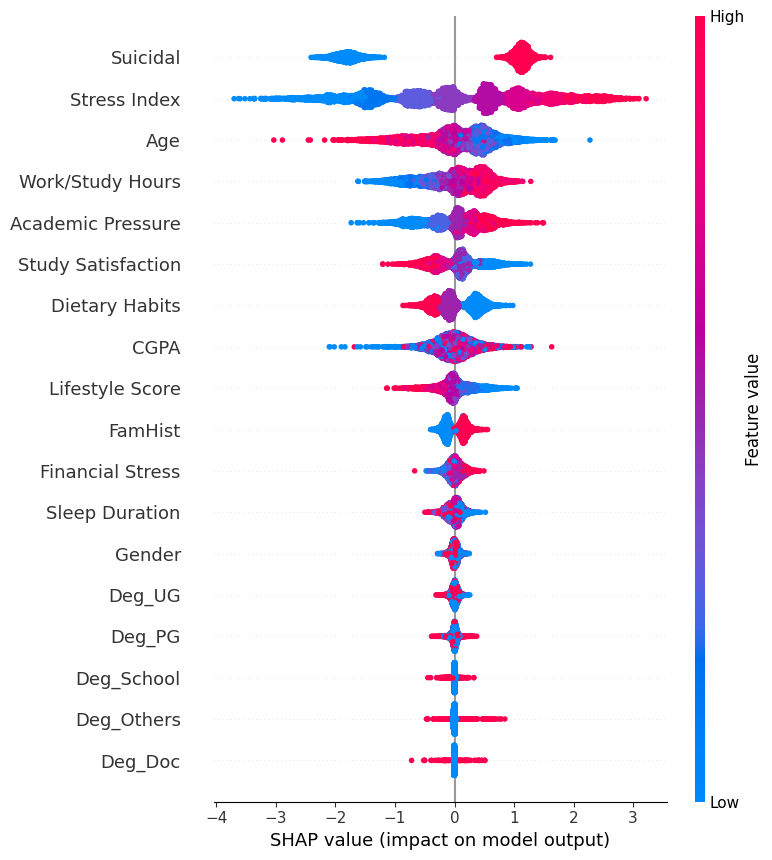


=== Mean |SHAP| top 10 ===
Suicidal              1.380
Stress Index          1.096
Age                   0.484
Work/Study Hours      0.404
Academic Pressure     0.382
Study Satisfaction    0.303
Dietary Habits        0.278
CGPA                  0.243
Lifestyle Score       0.198
FamHist               0.152
dtype: float32

Base value (log-odds): 0.385 -> probability 0.595


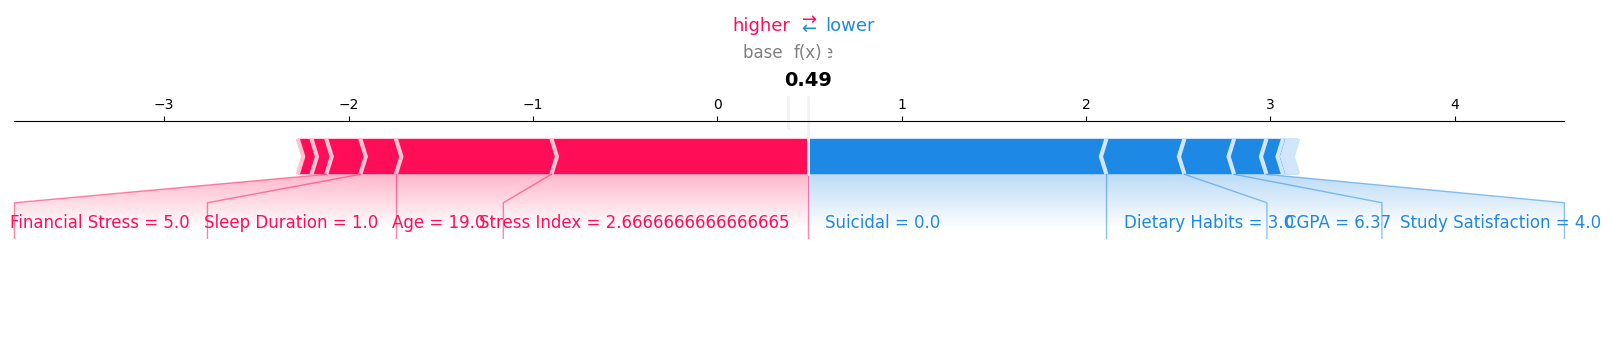


--- fig4_depressed: predicted prob=0.62, actual label=1 ---
                    value  SHAP
Suicidal         0.000000 -1.62
Stress Index     2.666667  1.39
Age             19.000000  0.84
Dietary Habits   3.000000 -0.42
CGPA             6.370000 -0.27
Sleep Duration   1.000000  0.19


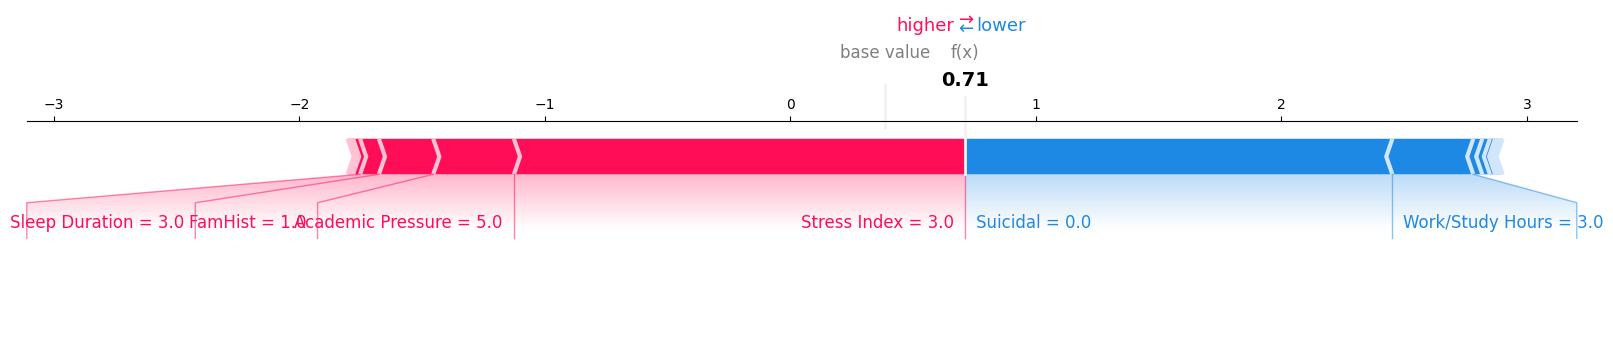


--- fig5_nondepressed_borderline: predicted prob=0.67, actual label=0 ---
                   value  SHAP
Stress Index         3.0  1.84
Suicidal             0.0 -1.74
Work/Study Hours     3.0 -0.33
Academic Pressure    5.0  0.33
FamHist              1.0  0.22
Sleep Duration       3.0  0.08


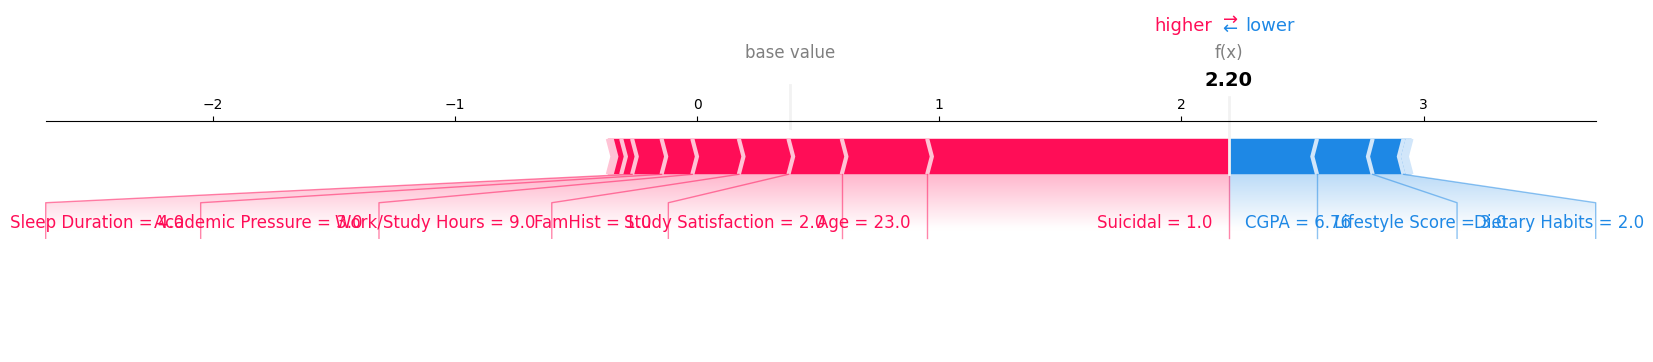


--- fig6_other: predicted prob=0.90, actual label=1 ---
                    value  SHAP
Suicidal             1.00  1.25
CGPA                 6.76 -0.36
Age                 23.00  0.35
Lifestyle Score      3.00 -0.23
Study Satisfaction   2.00  0.22
FamHist              1.00  0.20

DONE - copy ALL printed output (not the plots) back to Claude. Download the 4 PNG files from the Colab Files panel.


In [ ]:
# ===== Re-run Table IV + SHAP figures on the leakage-free pipeline =====
# Run this in the SAME Colab notebook, in a NEW cell AFTER revision_analysis.py has finished
# (it re-uses the variables Xtr, Xte, ytr, yte, main created there).
import shap, numpy as np, pandas as pd, matplotlib.pyplot as plt
cols=list(Xtr.columns)
rf_pipe=main['RF'][0]; xgb_pipe=main['XGB'][0]
rf=rf_pipe[-1]; xgb=xgb_pipe[-1]
Xte_i=pd.DataFrame(xgb_pipe[0].transform(Xte),columns=cols,index=Xte.index)   # test data imputed with TRAIN medians

# ---- Table IV ----
t4=pd.DataFrame({'RF':rf.feature_importances_,'XGB':xgb.feature_importances_},index=cols)
print('\n=== TABLE IV (top 10 by RF importance) ===');  print(t4.sort_values('RF',ascending=False).head(10).round(3))
print('\n=== Top 10 by XGB importance ===');             print(t4.sort_values('XGB',ascending=False).head(10).round(3))

# ---- Fig. 3: global SHAP summary ----
expl=shap.TreeExplainer(xgb); sv=expl.shap_values(Xte_i)
shap.summary_plot(sv,Xte_i,show=False); plt.savefig('fig3_shap_summary.png',dpi=300,bbox_inches='tight'); plt.show()
print('\n=== Mean |SHAP| top 10 ===')
print(pd.Series(np.abs(sv).mean(0),index=cols).sort_values(ascending=False).head(10).round(3))

# ---- Figs. 4-6: individual force plots ----
p=xgb_pipe.predict_proba(Xte)[:,1]; yv=yte.values
def pick(label,target):
    idx=np.where(yv==label)[0]; return idx[np.argmin(np.abs(p[idx]-target))]
cases={'fig4_depressed':pick(1,0.62),'fig5_nondepressed_borderline':pick(0,0.67),'fig6_other':pick(1,0.90)}
base=float(np.ravel(expl.expected_value)[0])
print('\nBase value (log-odds):',round(base,3),'-> probability',round(1/(1+np.exp(-base)),3))
for name,i in cases.items():
    shap.force_plot(base,sv[i],Xte_i.iloc[i],matplotlib=True,show=False)
    plt.savefig(name+'.png',dpi=300,bbox_inches='tight'); plt.show()
    top=pd.Series(sv[i],index=cols).sort_values(key=abs,ascending=False).head(6)
    print(f'\n--- {name}: predicted prob={p[i]:.2f}, actual label={yv[i]} ---')
    print(pd.DataFrame({'value':Xte_i.iloc[i][top.index],'SHAP':top.round(2)}))
print('\nDONE - copy ALL printed output (not the plots) back to Claude. Download the 4 PNG files from the Colab Files panel.')

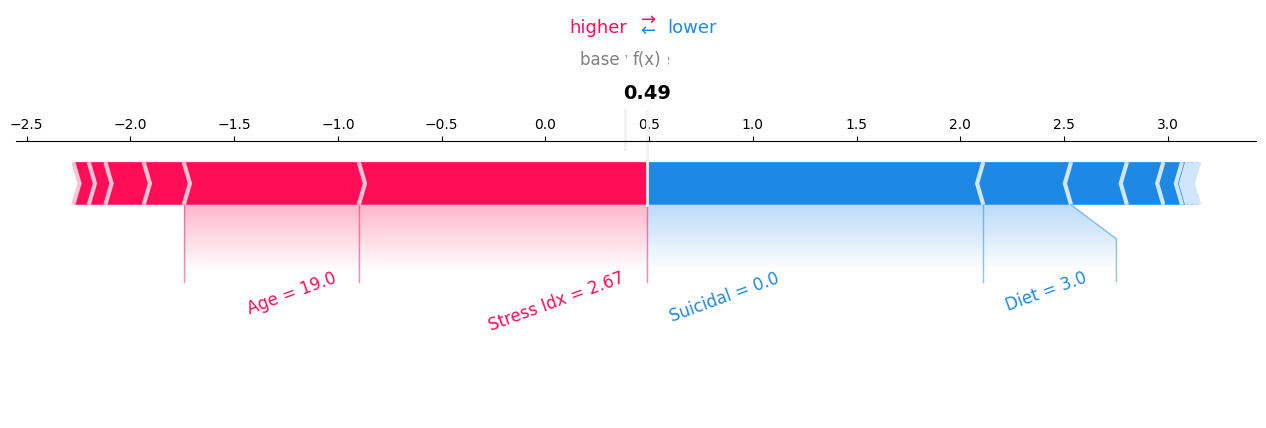

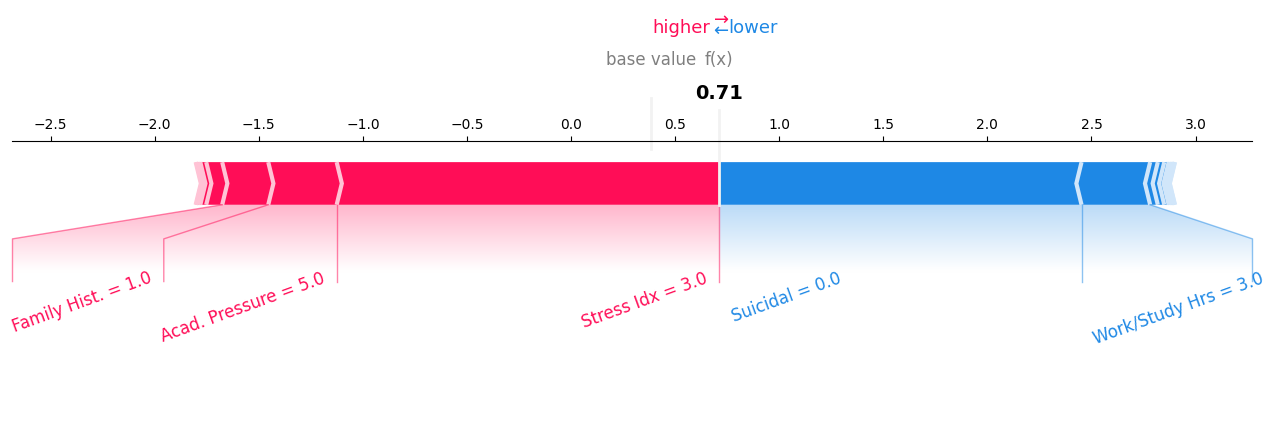

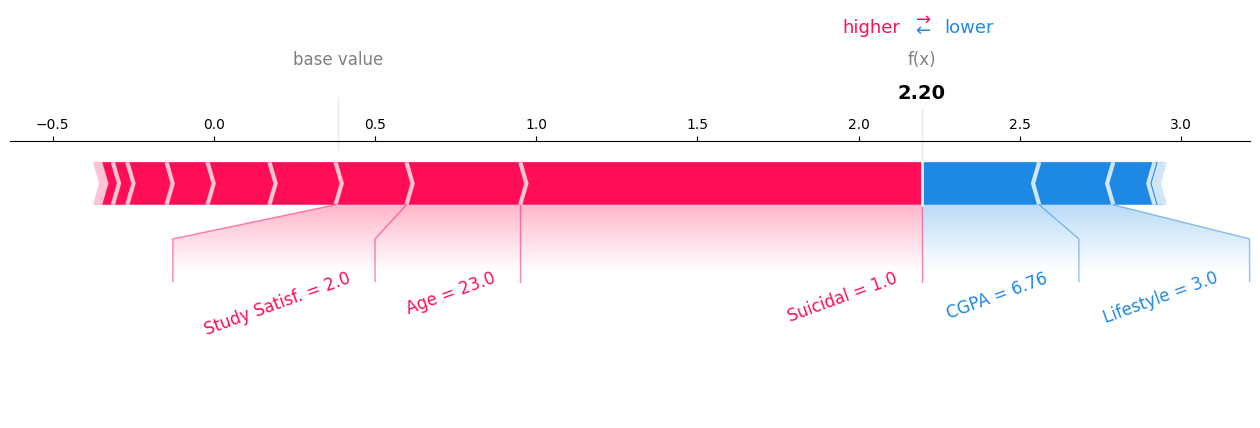

DONE - download the 3 *_clean.png files and upload them to Claude.


In [ ]:
# Cleaner force plots (readable labels). Run in the SAME Colab notebook, new cell,
# after rerun_table4_shap.py has been run (uses sv, Xte_i, base, cases, p, yv).
import shap, matplotlib.pyplot as plt
nice={'Financial Stress':'Fin. Stress','Sleep Duration':'Sleep','Academic Pressure':'Acad. Pressure',
      'Work/Study Hours':'Work/Study Hrs','Study Satisfaction':'Study Satisf.','Dietary Habits':'Diet',
      'Lifestyle Score':'Lifestyle','Stress Index':'Stress Idx','FamHist':'Family Hist.'}
names=[nice.get(c,c) for c in Xte_i.columns]
for name,i in cases.items():
    vals=Xte_i.iloc[i].round(2).values
    shap.force_plot(base,sv[i],vals,feature_names=names,matplotlib=True,show=False,
                    figsize=(16,3.6),text_rotation=20,contribution_threshold=0.12)
    plt.savefig(name+'_clean.png',dpi=300,bbox_inches='tight'); plt.show()
print('DONE - download the 3 *_clean.png files and upload them to Claude.')